In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
# Load the dataset exported from Part 1
df = pd.read_parquet('../data/network_intrusion_sampled.parquet')

# Separate Features (X) and Target Variable (y)
X = df.drop(columns=['Label'])
y = df['Label']

print(f"Full Dataset Shape: {df.shape}")

Full Dataset Shape: (503627, 26)


In [8]:
# We use stratify=y to ensure all classes are proportionally represented
X_temp_train, X_test, y_temp_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y 
)

print(f"Master Train Shape (For Grid Search): {X_temp_train.shape}")
print(f"Locked Test Shape (Do NOT touch yet): {X_test.shape}")

Master Train Shape (For Grid Search): (402901, 25)
Locked Test Shape (Do NOT touch yet): (100726, 25)


In [4]:
# Initialize StandardScaler to center the data (mean=0, variance=1)
scaler = StandardScaler()

# CRITICAL: Fit the scaler ONLY on the training data to prevent data leakage
X_temp_train_scaled = scaler.fit_transform(X_temp_train)

# ONLY transform the test set using the learned parameters
X_test_scaled = scaler.transform(X_test) 

# Convert the resulting numpy arrays back to DataFrames to preserve column names
X_temp_train_scaled = pd.DataFrame(X_temp_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

print("Standardization complete. Data centered to mean=0, variance=1.")

Standardization complete. Data centered to mean=0, variance=1.


In [5]:
import numpy as np
from sklearn.model_selection import PredefinedSplit

# 1. Create the Validation Set from our Temp Train data
# Using test_size=0.25 on 80% of the data gives us a 60/20/20 overall split
X_train, X_val, y_train, y_val = train_test_split(
    X_temp_train, y_temp_train, 
    test_size=0.25, 
    random_state=42, 
    stratify=y_temp_train
)

print(f"Scenario 1 Train Shape: {X_train.shape}")
print(f"Scenario 1 Val Shape:   {X_val.shape}")

# 2. Scale the data WITHOUT leakage
scaler_s1 = StandardScaler()

# Fit ONLY on the new training slice
X_train_scaled = scaler_s1.fit_transform(X_train)

# Transform the validation slice
X_val_scaled = scaler_s1.transform(X_val)

# (We will transform the Master Test set with this scaler at the very end of the project)

Scenario 1 Train Shape: (302175, 25)
Scenario 1 Val Shape:   (100726, 25)


In [6]:
# Create an array that tells GridSearchCV which rows are Train (-1) and which are Val (0)
split_index = [-1] * len(X_train_scaled) + [0] * len(X_val_scaled)
pds = PredefinedSplit(test_fold=split_index)

# Combine the data back together so GridSearchCV can slice it using our split_index
X_s1_combined = np.vstack((X_train_scaled, X_val_scaled))
y_s1_combined = np.concatenate((y_train, y_val))

print("Predefined Split created successfully for Scenario 1.")

Predefined Split created successfully for Scenario 1.


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# 1. Initialize the model with our imbalance solution
# max_iter is increased to ensure the model converges
log_reg = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)

# 2. Define appropriate hyperparameter ranges
# C: Inverse of regularization strength. Smaller values specify stronger regularization.
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs'] # saga is good for large datasets, lbfgs is default
}

# 3. Initialize GridSearchCV USING our PredefinedSplit (cv=pds)
grid_search_lr_s1 = GridSearchCV(
    estimator=log_reg,
    param_grid=param_grid_lr,
    cv=pds,             # This forces it to use our specific Train/Val split
    scoring='f1_macro', # F1 macro is excellent for imbalanced datasets
    n_jobs=-1,          # Uses all your CPU cores to speed things up
    verbose=2
)

# 4. Run the Grid Search
print("Starting Grid Search for Logistic Regression (Scenario 1)...")
grid_search_lr_s1.fit(X_s1_combined, y_s1_combined)

print("\n--- Logistic Regression (Scenario 1) Results ---")
print(f"Best Parameters: {grid_search_lr_s1.best_params_}")
print(f"Best Validation F1-Score: {grid_search_lr_s1.best_score_:.4f}")

# Save the best model for later comparison
best_lr_s1 = grid_search_lr_s1.best_estimator_

Starting Grid Search for Logistic Regression (Scenario 1)...
Fitting 1 folds for each of 5 candidates, totalling 5 fits
[CV] END ...............................C=0.01, solver=lbfgs; total time=  15.7s
[CV] END ................................C=0.1, solver=lbfgs; total time=  28.9s
[CV] END ..................................C=1, solver=lbfgs; total time= 1.0min
[CV] END .................................C=10, solver=lbfgs; total time= 1.8min


/Users/andreaskaramalikes/GitHub/Data-Mining-ML-Project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


[CV] END ................................C=100, solver=lbfgs; total time= 2.3min

--- Logistic Regression (Scenario 1) Results ---
Best Parameters: {'C': 100, 'solver': 'lbfgs'}
Best Validation F1-Score: 0.4422


In [18]:
import json

# Load label mapping from preprocessing step
with open('../data/label_mapping.json', 'r') as f:
    label_mapping = json.load(f)

# Reverse mapping: number -> class name
inverse_mapping = {v: k for k, v in label_mapping.items()}

# Ordered class names for reports
target_names = [inverse_mapping[i] for i in range(len(inverse_mapping))]

print("Loaded class labels:")
print(target_names)

Loaded class labels:
['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack � Brute Force', 'Web Attack � Sql Injection', 'Web Attack � XSS']


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# 1. Create the Pipeline
pipeline_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        solver='lbfgs',
        max_iter=2000,
        random_state=42
    ))
])

# 2. Parameter Grid
param_grid_lr_cv = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__tol': [1e-2, 1e-3]
}

# 3. Initialize K-Fold and GridSearchCV
kf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_lr_s2 = GridSearchCV(
    estimator=pipeline_lr,
    param_grid=param_grid_lr_cv,
    cv=kf,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=2
)

# 4. Run the Grid Search
print("Starting K-Fold Grid Search for Logistic Regression (Scenario 2)...")

grid_search_lr_s2.fit(X_temp_train, y_temp_train)

print("\n--- Logistic Regression Results ---")
print(f"Best Parameters: {grid_search_lr_s2.best_params_}")
print(f"Best Cross-Validation F1-Score: {grid_search_lr_s2.best_score_:.4f}")

# Save best model
best_lr_s2 = grid_search_lr_s2.best_estimator_

Starting K-Fold Grid Search for Logistic Regression (Scenario 2)...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END ...........classifier__C=0.01, classifier__tol=0.01; total time=   7.8s
[CV] END ...........classifier__C=0.01, classifier__tol=0.01; total time=   8.8s
[CV] END ...........classifier__C=0.01, classifier__tol=0.01; total time=   9.7s
[CV] END ...........classifier__C=0.01, classifier__tol=0.01; total time=  12.3s
[CV] END ...........classifier__C=0.01, classifier__tol=0.01; total time=  16.1s
[CV] END ............classifier__C=0.1, classifier__tol=0.01; total time=  13.3s
[CV] END ............classifier__C=0.1, classifier__tol=0.01; total time=   9.8s
[CV] END ............classifier__C=0.1, classifier__tol=0.01; total time=  18.3s
[CV] END ..........classifier__C=0.01, classifier__tol=0.001; total time=  33.9s
[CV] END ..........classifier__C=0.01, classifier__tol=0.001; total time=  34.7s
[CV] END ..........classifier__C=0.01, classifier__tol=0.001; 

EVALUATING SCENARIO 1 (Train/Validation Split Model)
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.76      0.86     83694
                       Bot       0.01      0.97      0.02        78
                      DDoS       0.89      1.00      0.94      5120
             DoS GoldenEye       0.40      0.94      0.56       411
                  DoS Hulk       0.95      0.94      0.95      6908
          DoS Slowhttptest       0.22      0.97      0.36       209
             DoS slowloris       0.13      0.92      0.23       215
               FTP-Patator       0.43      1.00      0.60       237
                Heartbleed       1.00      1.00      1.00         1
              Infiltration       0.00      1.00      0.01         7
                  PortScan       0.47      1.00      0.63      3628
               SSH-Patator       0.21      0.90      0.35       129
  Web Attack � Brute Force       0.00      0.05      0.01     

/Users/andreaskaramalikes/GitHub/Data-Mining-ML-Project/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


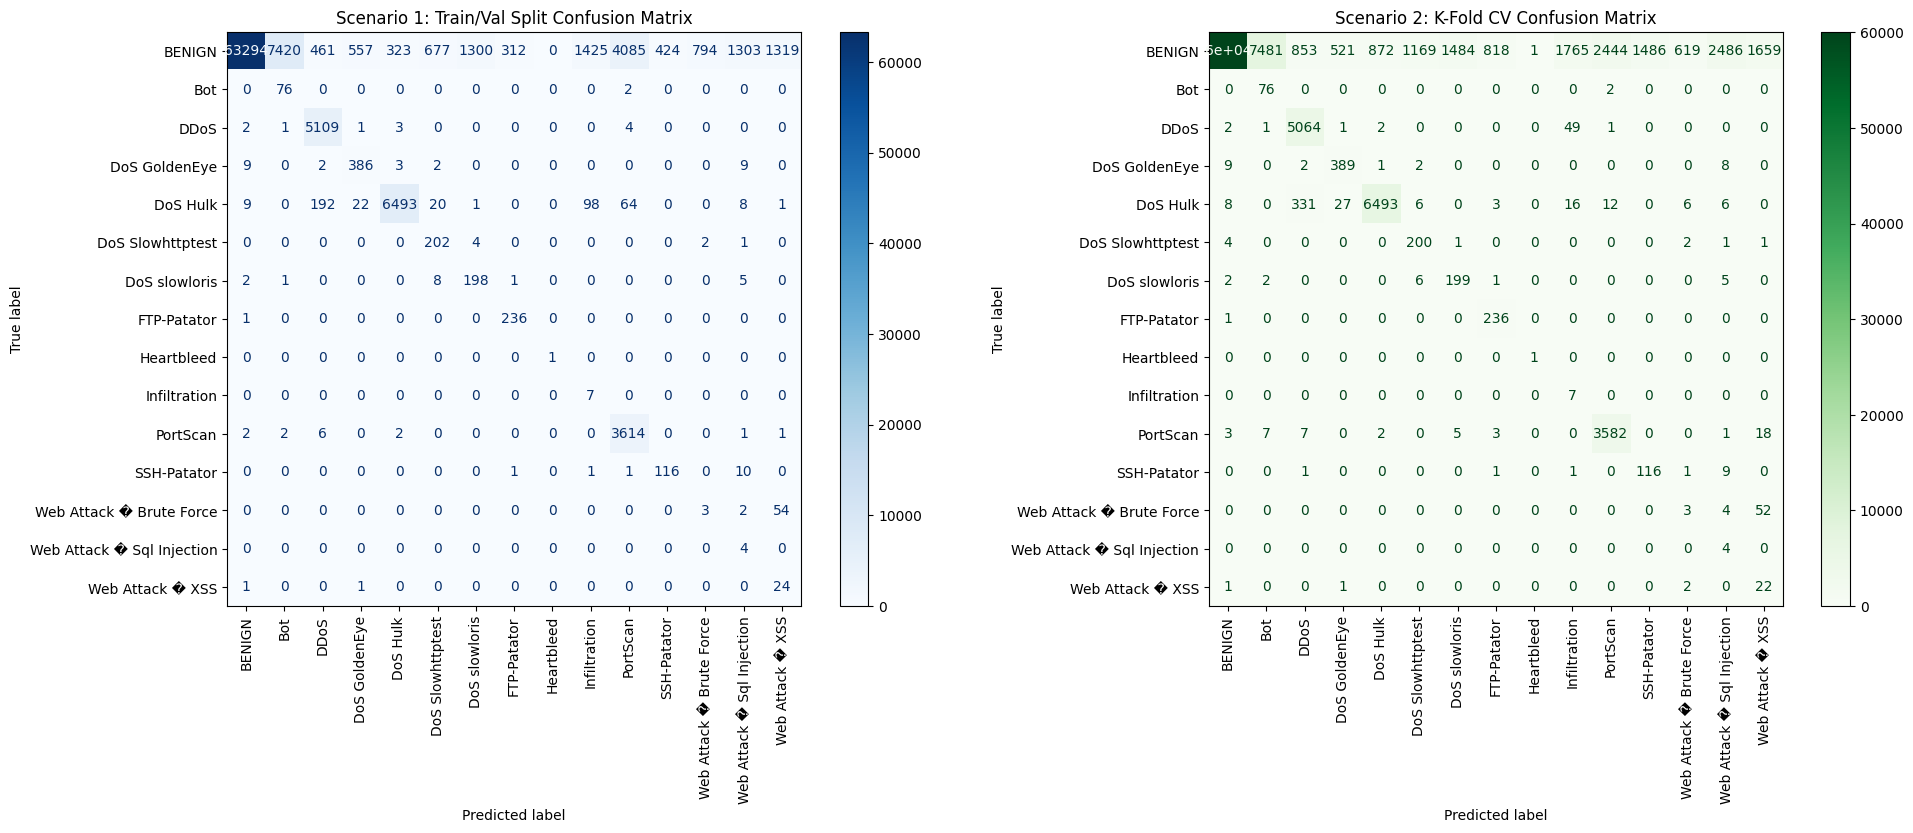

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Retrieve the target names you created in Part 1 to make the report readable
target_names = [inverse_mapping[i] for i in range(len(inverse_mapping))]

print("="*60)
print("EVALUATING SCENARIO 1 (Train/Validation Split Model)")
print("="*60)
# SCENARIO 1 PREDICTION: 
# We must use X_test_scaled because this model was not built inside a pipeline!
y_pred_s1 = best_lr_s1.predict(X_test_scaled)

print(classification_report(y_test, y_pred_s1, target_names=target_names))
print("\nConfusion Matrix (Scenario 1):")
print(confusion_matrix(y_test, y_pred_s1))

print("\n" + "="*60)
print("EVALUATING SCENARIO 2 (K-Fold Cross-Validation Model)")
print("="*60)
# SCENARIO 2 PREDICTION: 
# We must use the raw X_test because the pipeline handles the scaling automatically!
y_pred_s2 = best_lr_s2.predict(X_test)

print(classification_report(y_test, y_pred_s2, target_names=target_names))
print("\nConfusion Matrix (Scenario 2):")
print(confusion_matrix(y_test, y_pred_s2))